In [1]:
from google.colab import files
uploaded = files.upload()

Saving rainfall.csv to rainfall.csv


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv('rainfall.csv')

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
Dataset shape: (54, 6)
Columns: ['date', 'rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition']


In [4]:
print(df.isnull().sum())

date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
dtype: int64


In [5]:
df.shape
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

In [6]:
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [7]:
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


In [9]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')


In [10]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


In [12]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


In [13]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


In [15]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


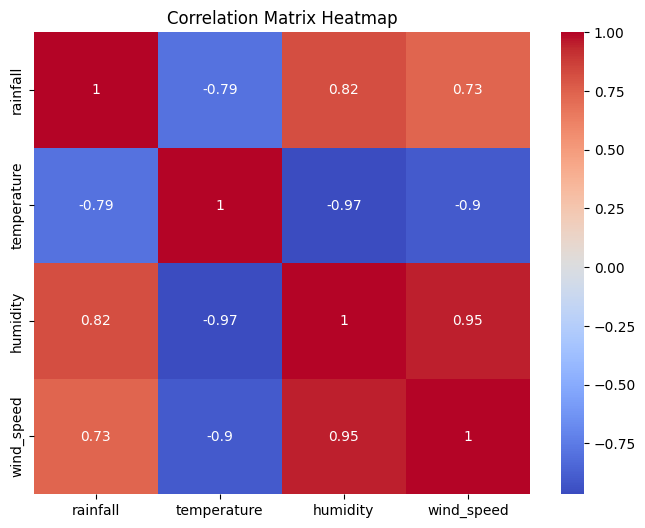

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [17]:
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


In [18]:
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

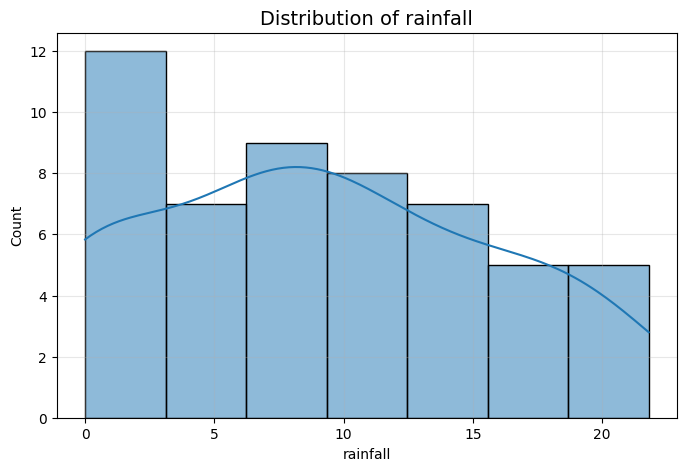

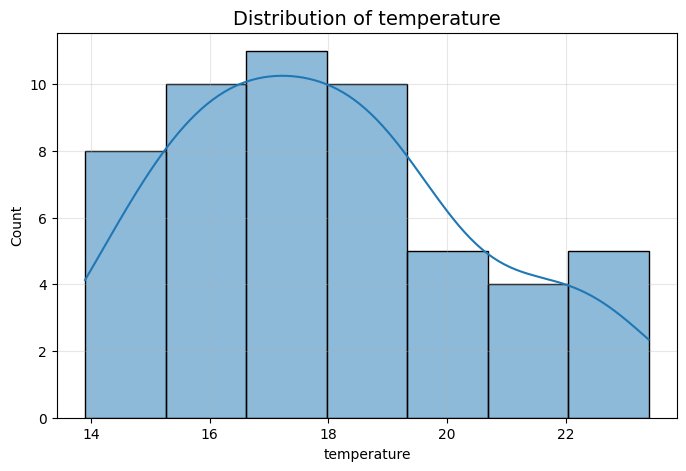

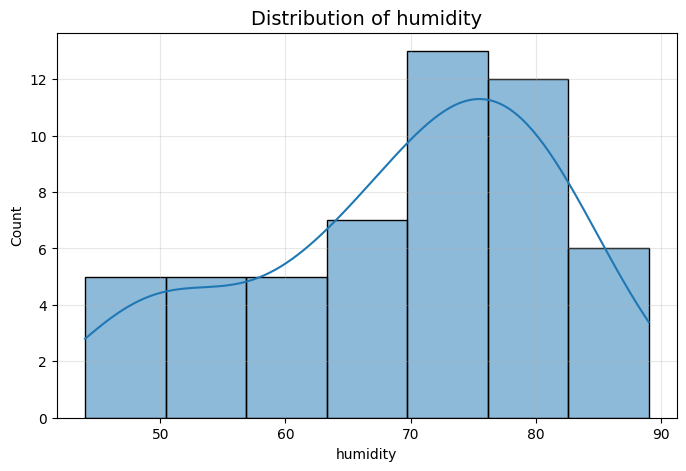

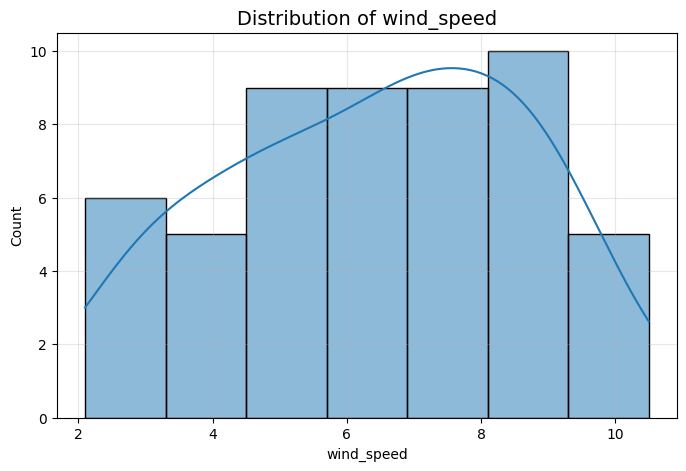

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)
    plt.show()

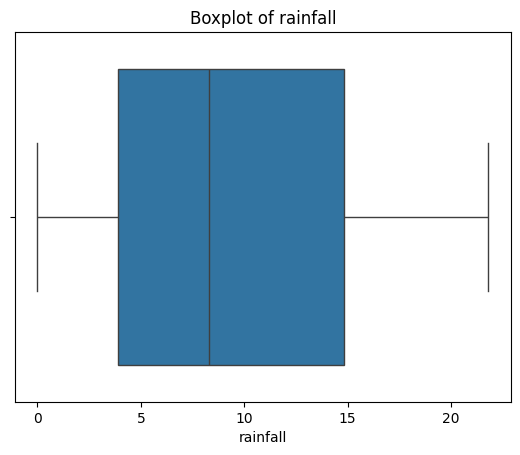

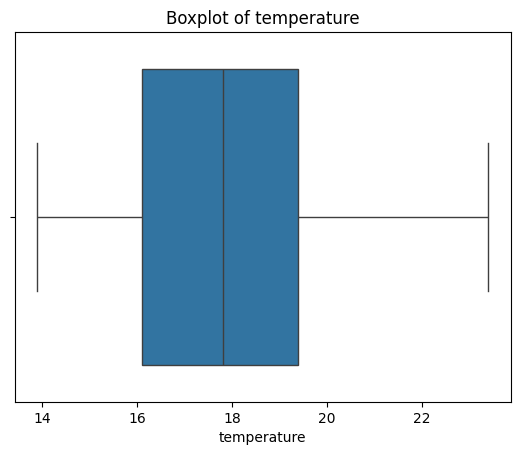

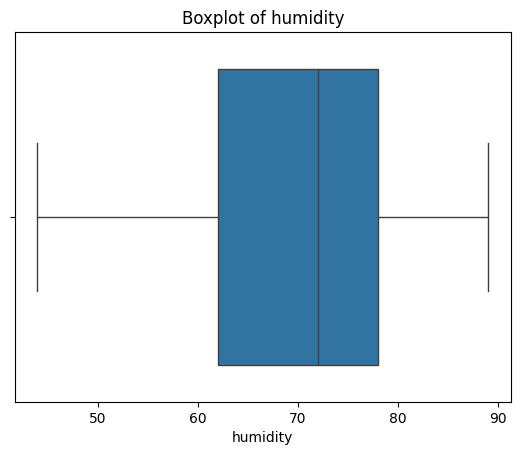

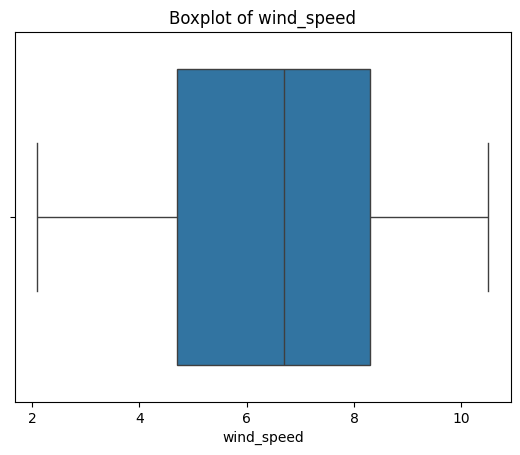

In [20]:
import seaborn as sns

for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

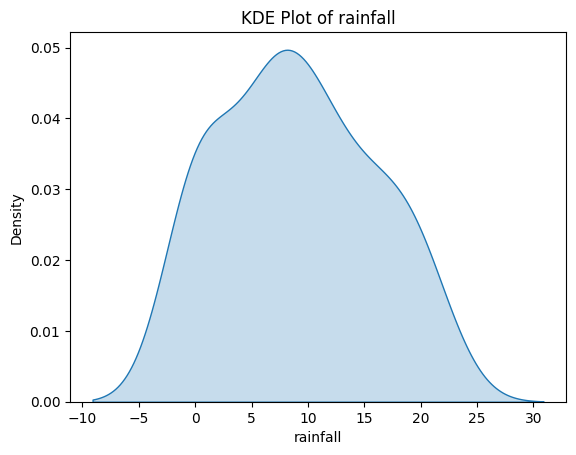

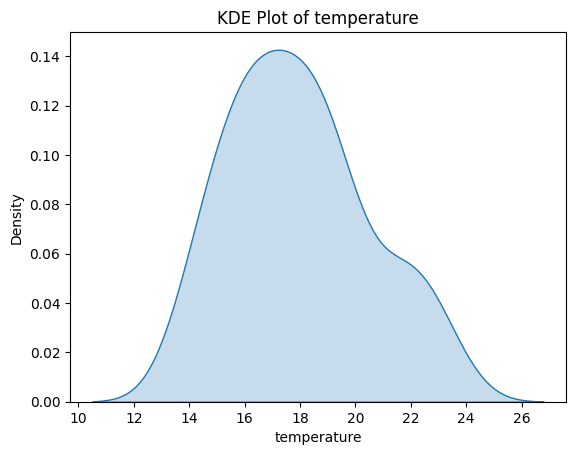

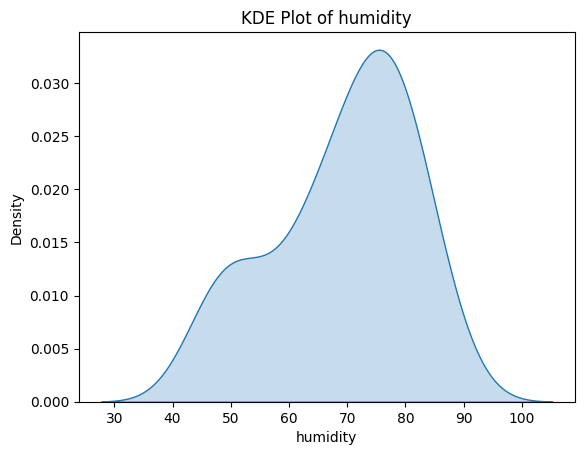

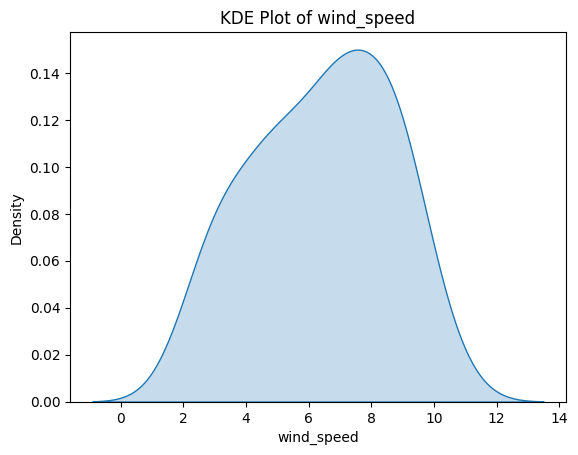

In [21]:
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

In [23]:
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


In [24]:
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


In [26]:
if "weather_condition" in df.columns and "rainfall" in df.columns:
    avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()
    print("Average Rainfall by Weather Condition:")
    print(avg_rainfall)

else:
    print("Required columns not found in the dataset.")

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


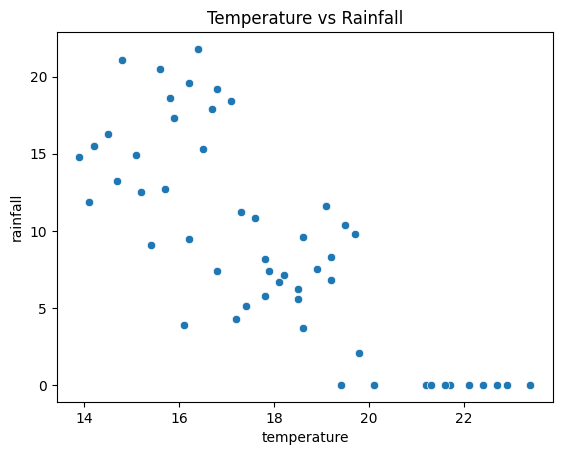

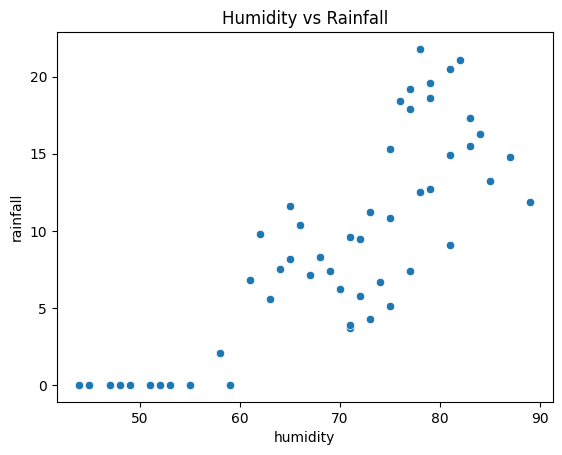

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()
sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

Basic Questions

In [28]:
print(df.head(10))

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
5  2022-01-06      15.3         16.5      75.0         7.8             Rainy
6  2022-01-07       6.8         19.2      61.0         4.5             Rainy
7  2022-01-08       0.0         21.7      48.0         2.9             Sunny
8  2022-01-09      11.2         17.3      73.0         6.1             Rainy
9  2022-01-10      18.6         15.8      79.0         8.9             Rainy


In [29]:
print("Rows and columns:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Rows and columns: (54, 6)
Number of rows: 54
Number of columns: 6


In [30]:
print(df.columns.tolist())

['date', 'rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition']


In [31]:
print(df.dtypes)

date                  object
rainfall             float64
temperature          float64
humidity             float64
wind_speed           float64
weather_condition     object
dtype: object


In [32]:
print(df.isnull().sum())

date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
dtype: int64


In [33]:
print("Mean:", df['rainfall'].mean())
print("Median:", df['rainfall'].median())
print("Standard Deviation:", df['rainfall'].std())

Mean: 9.049056603773584
Median: 8.3
Standard Deviation: 6.712520524005565


In [34]:
print("Maximum temperature:", df['temperature'].max())
print("Minimum temperature:", df['temperature'].min())

Maximum temperature: 23.4
Minimum temperature: 13.9


In [35]:
numeric_df = df.select_dtypes(include=np.number)
print(numeric_df.head())
print("Numerical columns:", numeric_df.columns.tolist())

   rainfall  temperature  humidity  wind_speed
0      12.5         15.2      78.0         8.5
1       8.2         17.8      65.0         5.2
2       0.0         20.1      52.0         3.1
3       3.7         18.6      71.0         6.7
4      21.1         14.8      82.0         9.3
Numerical columns: ['rainfall', 'temperature', 'humidity', 'wind_speed']


Correlation Coding

In [36]:
corr_matrix = numeric_df.corr()
print(corr_matrix)

             rainfall  temperature  humidity  wind_speed
rainfall     1.000000    -0.790566  0.821357    0.733376
temperature -0.790566     1.000000 -0.966097   -0.902996
humidity     0.821357    -0.966097  1.000000    0.951643
wind_speed   0.733376    -0.902996  0.951643    1.000000


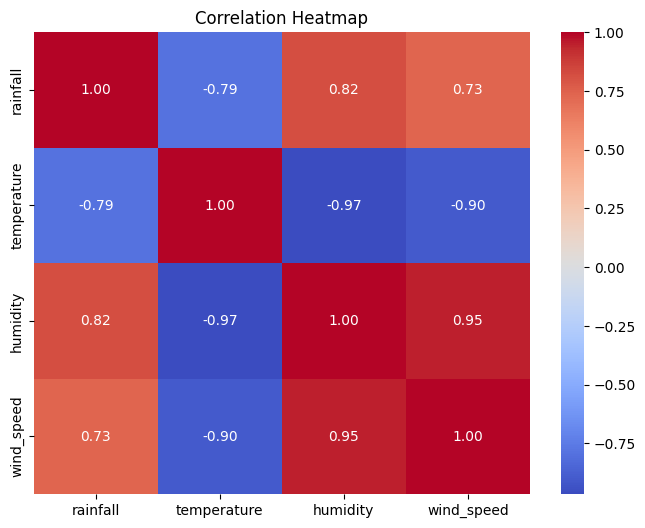

In [37]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [38]:
rainfall_corr = corr_matrix['rainfall'].sort_values(ascending=False)
print(rainfall_corr)

rainfall       1.000000
humidity       0.821357
wind_speed     0.733376
temperature   -0.790566
Name: rainfall, dtype: float64


In [39]:
corr_pairs = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack()

print(corr_pairs[corr_pairs > 0.7])

rainfall  humidity      0.821357
          wind_speed    0.733376
humidity  wind_speed    0.951643
dtype: float64


In [40]:
high_corr_features = list(
    set(corr_pairs[corr_pairs > 0.7].index.get_level_values(0)) |
    set(corr_pairs[corr_pairs > 0.7].index.get_level_values(1))
)

print("Highly correlated features:", high_corr_features)

Highly correlated features: ['rainfall', 'humidity', 'wind_speed']


In [41]:
pairs = corr_pairs[corr_pairs > 0.7].index.tolist()
drop_features = []

for f1, f2 in pairs:
    if f1 == 'rainfall':
        drop_features.append(f2)
    elif f2 == 'rainfall':
        drop_features.append(f1)
    else:
        drop_features.append(f2)

reduced_df = numeric_df.drop(
    columns=list(set(drop_features))
)

print("Dropped features:", list(set(drop_features)))
print(reduced_df.head())

Dropped features: ['humidity', 'wind_speed']
   rainfall  temperature
0      12.5         15.2
1       8.2         17.8
2       0.0         20.1
3       3.7         18.6
4      21.1         14.8


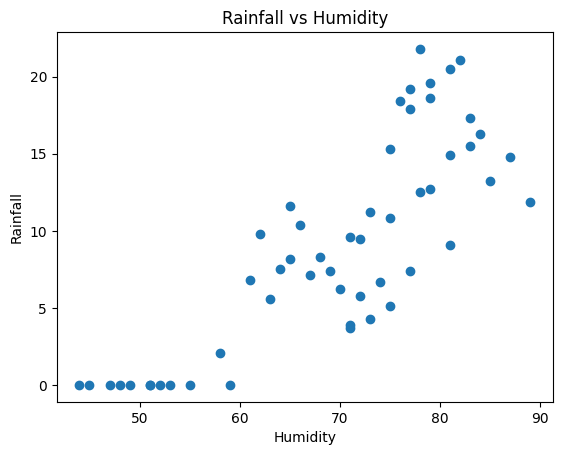

In [42]:
plt.scatter(df['humidity'], df['rainfall'])
plt.xlabel("Humidity")
plt.ylabel("Rainfall")
plt.title("Rainfall vs Humidity")
plt.show()

Distribution Coding

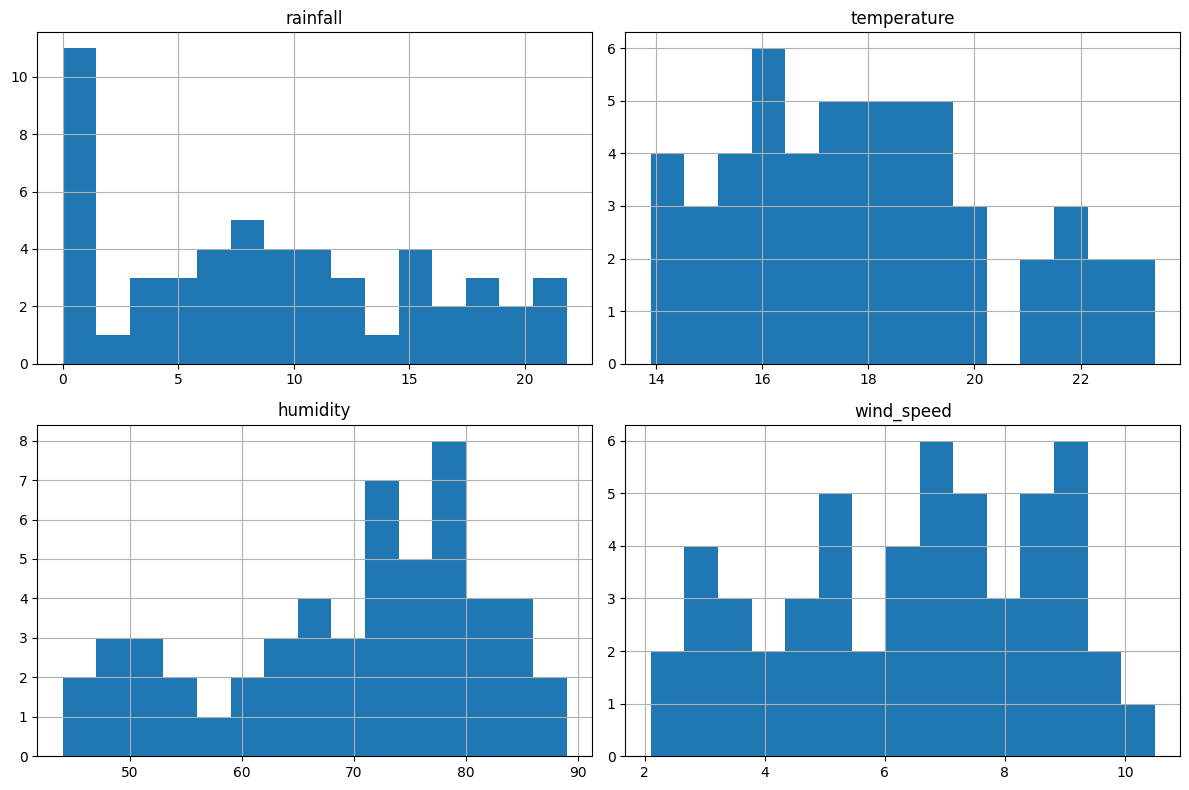

In [43]:
numeric_df.hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

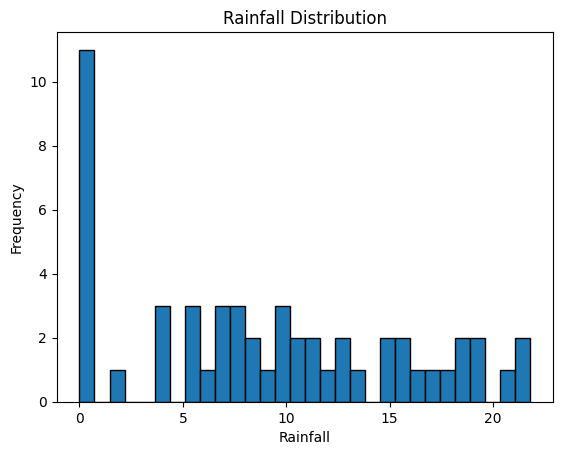

In [44]:
plt.hist(df['rainfall'].dropna(), bins=30, edgecolor='black')
plt.xlabel("Rainfall")
plt.ylabel("Frequency")
plt.title("Rainfall Distribution")
plt.show()

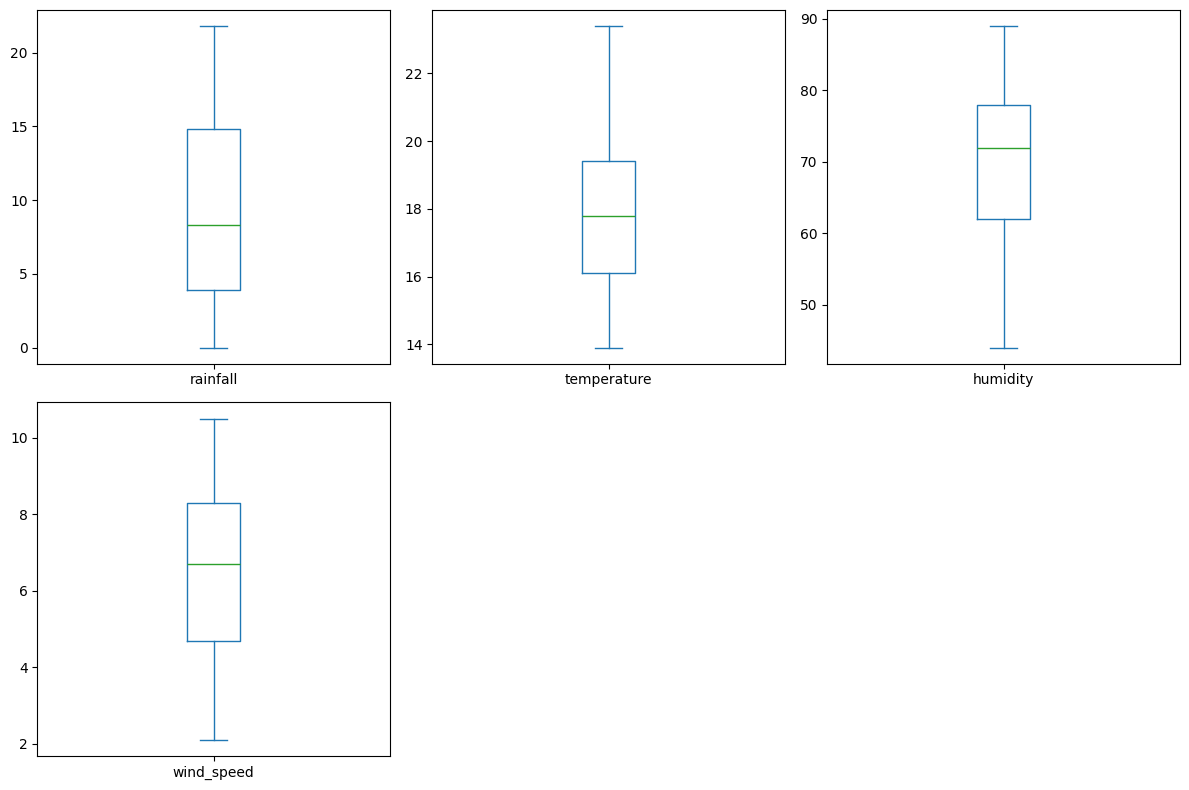

In [45]:
numeric_df.plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(12, 8)
)
plt.tight_layout()
plt.show()

In [46]:
for col in numeric_df.columns:
    Q1 = numeric_df[col].quantile(0.25)
    Q3 = numeric_df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = numeric_df[
        (numeric_df[col] < Q1 - 1.5 * IQR) |
        (numeric_df[col] > Q3 + 1.5 * IQR)
    ]

    print(col, "outliers:", len(outliers))

rainfall outliers: 0
temperature outliers: 0
humidity outliers: 0
wind_speed outliers: 0


In [47]:
print(numeric_df.skew())

rainfall       0.191925
temperature    0.436075
humidity      -0.564768
wind_speed    -0.207329
dtype: float64


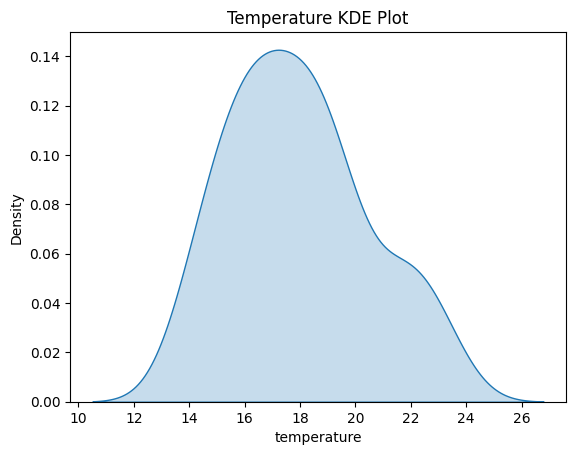

In [48]:
sns.kdeplot(data=df, x='temperature', fill=True)
plt.title("Temperature KDE Plot")
plt.show()

In [49]:
mean_rain = df['rainfall'].mean()
median_rain = df['rainfall'].median()

print("Mean:", mean_rain)
print("Median:", median_rain)

if mean_rain > median_rain:
    print("Mean is greater than median.")
elif mean_rain < median_rain:
    print("Median is greater than mean.")
else:
    print("Mean and median are equal.")

Mean: 9.049056603773584
Median: 8.3
Mean is greater than median.


In [50]:
skewness = numeric_df.skew()
right_skewed = skewness[skewness > 0]

print("Right-skewed features:", right_skewed.index.tolist())
print("Count:", len(right_skewed))

Right-skewed features: ['rainfall', 'temperature']
Count: 2


Insights Coding

In [51]:
print(df.groupby('weather_condition')['rainfall'].mean())

weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


In [52]:
print(df.nlargest(3, 'rainfall'))

          date  rainfall  temperature  humidity  wind_speed weather_condition
29  2022-01-30      21.8         16.4      78.0         7.6             Rainy
4   2022-01-05      21.1         14.8      82.0         9.3             Rainy
44  2022-02-14      20.5         15.6      81.0         8.2             Rainy


In [53]:
avg_rainfall = df['rainfall'].mean()

above_average = df[df['rainfall'] > avg_rainfall]
print(above_average)

          date  rainfall  temperature  humidity  wind_speed weather_condition
0   2022-01-01      12.5         15.2      78.0         8.5             Rainy
4   2022-01-05      21.1         14.8      82.0         9.3             Rainy
5   2022-01-06      15.3         16.5      75.0         7.8             Rainy
8   2022-01-09      11.2         17.3      73.0         6.1             Rainy
9   2022-01-10      18.6         15.8      79.0         8.9             Rainy
10  2022-01-11       9.5         16.2      72.0         5.7             Rainy
14  2022-01-15      14.9         15.1      81.0         8.7             Rainy
15  2022-01-16      19.2         16.8      77.0         7.2             Rainy
18  2022-01-19      10.8         17.6      75.0         6.7             Rainy
19  2022-01-20      16.3         14.5      84.0         9.1             Rainy
23  2022-01-24      12.7         15.7      79.0         8.3             Rainy
24  2022-01-25      18.4         17.1      76.0         6.8     

In [54]:
avg_rainfall = df['rainfall'].mean()

high_rain = df[df['rainfall'] > avg_rainfall]
low_rain = df[df['rainfall'] <= avg_rainfall]

print("High rainfall temperature:", high_rain['temperature'].mean())
print("Low rainfall temperature:", low_rain['temperature'].mean())

High rainfall temperature: 16.253846153846155
Low rainfall temperature: 19.585185185185182


In [55]:
df['high_rainfall'] = (
    df['rainfall'] > df['rainfall'].mean()
).astype(int)

print(df[['rainfall', 'high_rainfall']].head(10))

   rainfall  high_rainfall
0      12.5              1
1       8.2              0
2       0.0              0
3       3.7              0
4      21.1              1
5      15.3              1
6       6.8              0
7       0.0              0
8      11.2              1
9      18.6              1


In [56]:
print(df['high_rainfall'].value_counts())
print("High rainfall records:", (df['high_rainfall'] == 1).sum())

high_rainfall
0    28
1    26
Name: count, dtype: int64
High rainfall records: 26


In [57]:
high_rain_df = df[df['high_rainfall'] == 1]

high_rain_corr = high_rain_df.select_dtypes(
    include=np.number
).corr()

print(high_rain_corr)

               rainfall  temperature  humidity  wind_speed  high_rainfall
rainfall       1.000000    -0.345569  0.409248    0.324545            NaN
temperature   -0.345569     1.000000 -0.943597   -0.916880            NaN
humidity       0.409248    -0.943597  1.000000    0.940413            NaN
wind_speed     0.324545    -0.916880  0.940413    1.000000            NaN
high_rainfall       NaN          NaN       NaN         NaN            NaN


Advanced Coding

In [58]:
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

print(detect_outliers(df, 'rainfall'))

Empty DataFrame
Columns: [date, rainfall, temperature, humidity, wind_speed, weather_condition, high_rainfall]
Index: []


In [59]:
Q1 = df['rainfall'].quantile(0.25)
Q3 = df['rainfall'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[
    df['rainfall'].between(lower, upper)
].copy()

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_no_outliers))

Original rows: 54
Rows after removing outliers: 53


In [60]:
numeric_cols = df.select_dtypes(include=np.number).columns
minmax_scaler = MinMaxScaler()
normalized_df = df.copy()
normalized_df[numeric_cols] = minmax_scaler.fit_transform(
    df[numeric_cols]
)

print(normalized_df.head())

         date  rainfall  temperature  humidity  wind_speed weather_condition  \
0  2022-01-01  0.573394     0.136842  0.755556    0.761905             Rainy   
1  2022-01-02  0.376147     0.410526  0.466667    0.369048             Rainy   
2  2022-01-03  0.000000     0.652632  0.177778    0.119048             Sunny   
3  2022-01-04  0.169725     0.494737  0.600000    0.547619             Rainy   
4  2022-01-05  0.967890     0.094737  0.844444    0.857143             Rainy   

   high_rainfall  
0            1.0  
1            0.0  
2            0.0  
3            0.0  
4            1.0  


In [61]:
numeric_cols = df.select_dtypes(include=np.number).columns
minmax_scaler = MinMaxScaler()
normalized_df = df.copy()
normalized_df[numeric_cols] = minmax_scaler.fit_transform(
    df[numeric_cols]
)

print(normalized_df.head())

         date  rainfall  temperature  humidity  wind_speed weather_condition  \
0  2022-01-01  0.573394     0.136842  0.755556    0.761905             Rainy   
1  2022-01-02  0.376147     0.410526  0.466667    0.369048             Rainy   
2  2022-01-03  0.000000     0.652632  0.177778    0.119048             Sunny   
3  2022-01-04  0.169725     0.494737  0.600000    0.547619             Rainy   
4  2022-01-05  0.967890     0.094737  0.844444    0.857143             Rainy   

   high_rainfall  
0            1.0  
1            0.0  
2            0.0  
3            0.0  
4            1.0  


In [62]:
standard_scaler = StandardScaler()
standardized_df = df.copy()
standardized_df[numeric_cols] = standard_scaler.fit_transform(
    df[numeric_cols]
)

print(standardized_df.head())

         date  rainfall  temperature  humidity  wind_speed weather_condition  \
0  2022-01-01  0.519025    -1.110613  0.738427    0.957999             Rainy   
1  2022-01-02 -0.127699    -0.060939 -0.358073   -0.550138             Rainy   
2  2022-01-03 -1.360987     0.867619 -1.454573   -1.509862             Sunny   
3  2022-01-04 -0.804503     0.262038  0.148004    0.135379             Rainy   
4  2022-01-05  1.812474    -1.272101  1.075811    1.323608             Rainy   

   high_rainfall  
0       1.037749  
1      -0.963624  
2      -0.963624  
3      -0.963624  
4       1.037749  


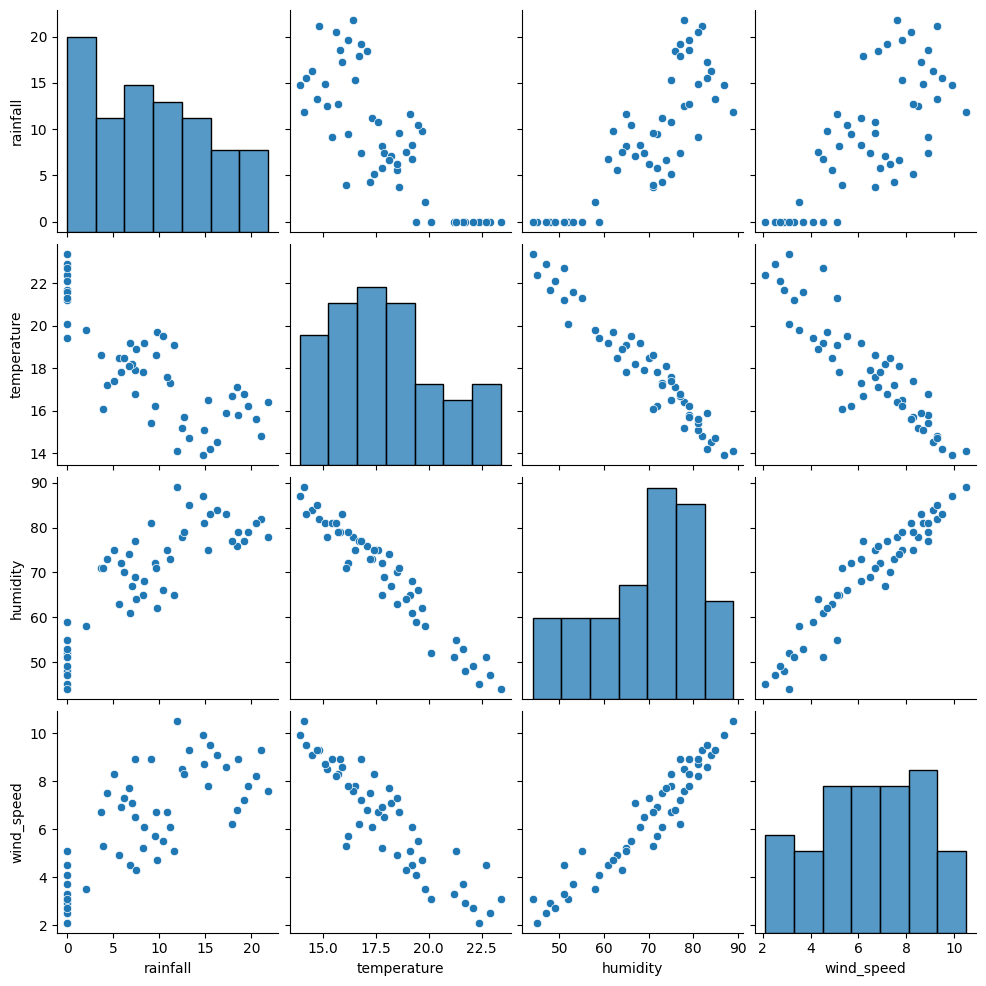

In [63]:
selected_features = [
    'rainfall', 'temperature', 'humidity', 'wind_speed'
]

sns.pairplot(df[selected_features].dropna())
plt.show()

In [64]:
corr = df.select_dtypes(include=np.number).corr()['rainfall']
important_features = corr[
    (corr > 0.5) & (corr.index != 'rainfall')
]

print("Features positively correlated with rainfall (> 0.5):")
print(important_features)

Features positively correlated with rainfall (> 0.5):
humidity         0.821357
wind_speed       0.733376
high_rainfall    0.841399
Name: rainfall, dtype: float64


weather_condition
Rainy    42
Sunny    11
Name: count, dtype: int64

Class percentages:
weather_condition
Rainy    79.245283
Sunny    20.754717
Name: proportion, dtype: float64


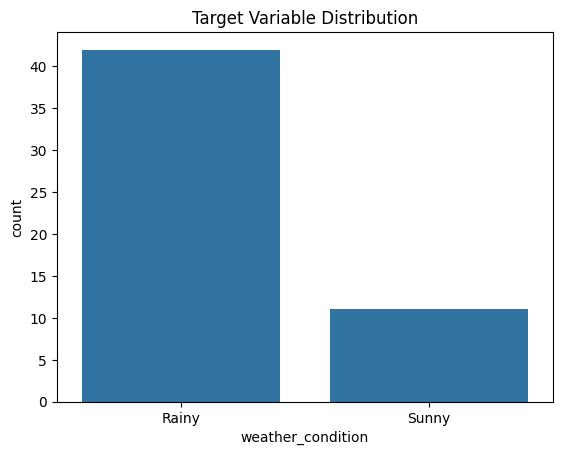

In [65]:
target = 'weather_condition'
print(df[target].value_counts())
print("\nClass percentages:")
print(df[target].value_counts(normalize=True) * 100)

sns.countplot(data=df, x=target)
plt.title("Target Variable Distribution")
plt.show()

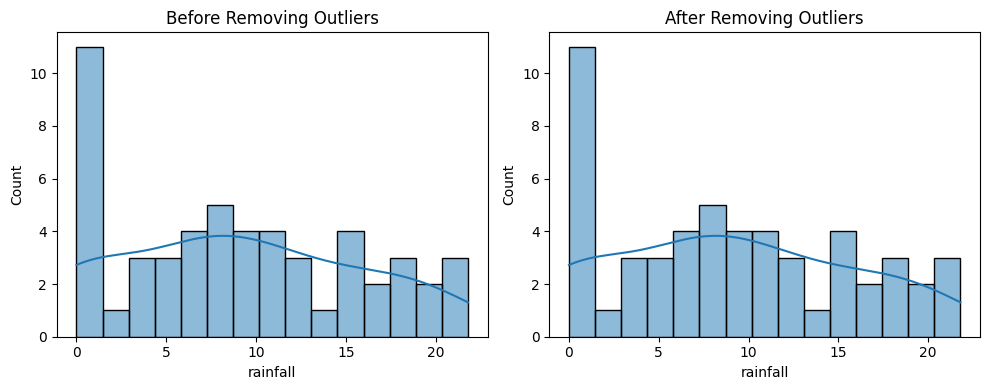

In [66]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['rainfall'], bins=15, kde=True)
plt.title("Before Removing Outliers")
plt.subplot(1, 2, 2)
sns.histplot(df_no_outliers['rainfall'], bins=15, kde=True)
plt.title("After Removing Outliers")
plt.tight_layout()
plt.show()

In [67]:
summary = pd.DataFrame({
    'Mean': numeric_df.mean(),
    'Skewness': numeric_df.skew(),
    'Outliers_Count': [
        len(detect_outliers(df, col))
        for col in numeric_df.columns
    ]
})

print(summary)

                  Mean  Skewness  Outliers_Count
rainfall      9.049057  0.191925               0
temperature  17.950943  0.436075               0
humidity     69.245283 -0.564768               0
wind_speed    6.403774 -0.207329               0


===== BASIC INFORMATION =====
Shape: (54, 7)

Columns:
['date', 'rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition', 'high_rainfall']

Data types:
date                  object
rainfall             float64
temperature          float64
humidity             float64
wind_speed           float64
weather_condition     object
high_rainfall          int64
dtype: object

Missing values:
date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
high_rainfall        0
dtype: int64

Statistical summary:
        rainfall  temperature   humidity  wind_speed  high_rainfall
count  53.000000    53.000000  53.000000   53.000000      54.000000
mean    9.049057    17.950943  69.245283    6.403774       0.481481
std     6.712521     2.500663  11.969361    2.209069       0.504349
min     0.000000    13.900000  44.000000    2.100000       0.000000
25%     3.900000    16.100000  62.000000    4.700000       0.0

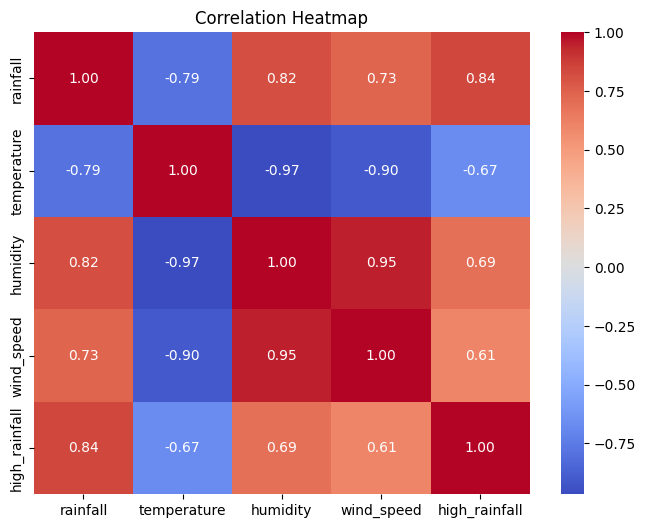


===== DISTRIBUTIONS =====


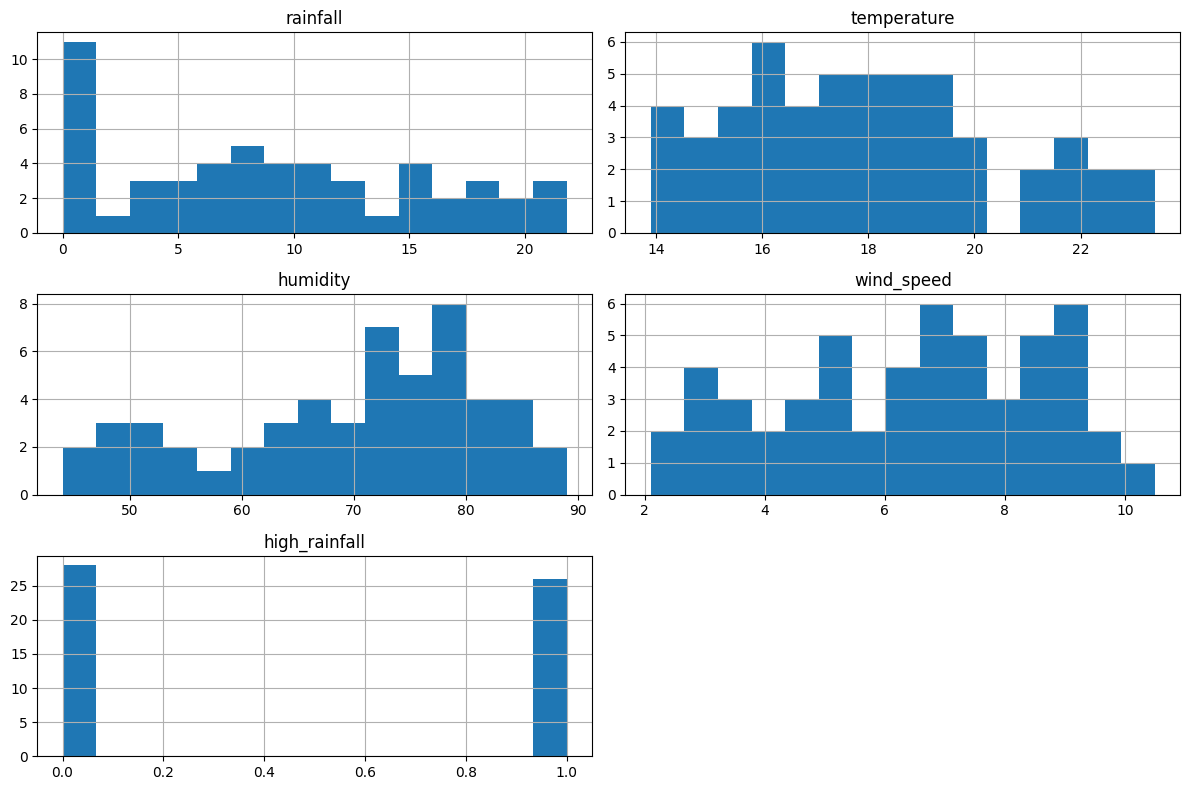


Skewness:
rainfall         0.191925
temperature      0.436075
humidity        -0.564768
wind_speed      -0.207329
high_rainfall    0.076260
dtype: float64

Outlier counts:
rainfall 0
temperature 0
humidity 0
wind_speed 0
high_rainfall 0

EDA completed successfully!


In [68]:
def full_eda(data):
    numeric = data.select_dtypes(include=np.number)

    print("===== BASIC INFORMATION =====")
    print("Shape:", data.shape)
    print("\nColumns:")
    print(data.columns.tolist())
    print("\nData types:")
    print(data.dtypes)
    print("\nMissing values:")
    print(data.isnull().sum())
    print("\nStatistical summary:")
    print(data.describe())
    print("\n===== CORRELATION =====")
    corr = numeric.corr()
    print(corr)

    if not corr.empty:
        plt.figure(figsize=(8, 6))
        sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
        plt.title("Correlation Heatmap")
        plt.show()

    print("\n===== DISTRIBUTIONS =====")
    if not numeric.empty:
        numeric.hist(figsize=(12, 8), bins=15)
        plt.tight_layout()
        plt.show()

        print("\nSkewness:")
        print(numeric.skew())
        print("\nOutlier counts:")
        for col in numeric.columns:
            print(col, len(detect_outliers(data, col)))

    print("\nEDA completed successfully!")

full_eda(df)